In [2]:
import h5py
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import numpy as np
import json

import matplotlib.lines as mlines


In [3]:
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/cr_bowshock_outputs"
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission_revised"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

# sims for which we compare pmax at the outer shock vs pmax at the termination shock
sim_names_compare = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]


## Outer shock vs termination shock $p_\mathrm{max}$: synchrotron luminosity comparison

### Time-averaged synchrotron luminosity vs frequency

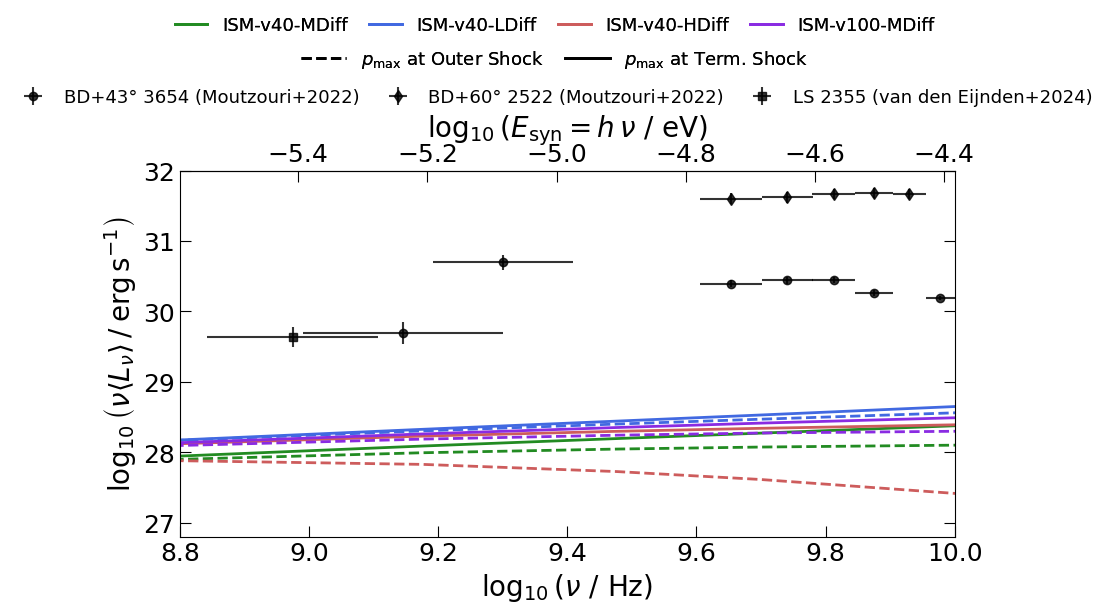

In [4]:
fig_tseries, ax_tseries = plt.subplots(figsize=(10, 6))

sim_handles = []
for i, sim_name in enumerate(sim_names_compare):

    # --- outer shock pmax (dashed) ---
    with h5py.File(f"{data_dir}/emission_data_synch.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch.h5, skipping outer shock curve")
        else:
            times = pf[sim_name]["times"][()] * u.kyr
            synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)
            synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz

            synch_lum = synch_lum[np.argsort(times)]
            times = np.sort(times)
            synch_lum_tavg = np.mean(synch_lum, axis=0)

            ax_tseries.plot(
                np.log10(synch_freq_grid.to_value(u.Hz)),
                np.log10((synch_freq_grid.to(u.Hz) * synch_lum_tavg).to_value(u.erg / u.s)),
                color=bowshock_config[sim_name]["color"],
                label=sim_name,
                ls="--",
                lw=2.0,
            )

    # --- termination shock pmax (solid) ---
    with h5py.File(f"{data_dir}/emission_data_synch_term.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch_term.h5, skipping termination shock curve")
        else:
            times = pf[sim_name]["times"][()] * u.kyr
            synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)
            synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz

            synch_lum = synch_lum[np.argsort(times)]
            times = np.sort(times)
            synch_lum_tavg = np.mean(synch_lum, axis=0)

            ax_tseries.plot(
                np.log10(synch_freq_grid.to_value(u.Hz)),
                np.log10((synch_freq_grid.to(u.Hz) * synch_lum_tavg).to_value(u.erg / u.s)),
                color=bowshock_config[sim_name]["color"],
                label=sim_name,
                ls="-",
                lw=2.0,
            )

    sim_handles.append(
        mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color=bowshock_config[sim_name]["color"],
            label=bowshock_config[sim_name]["label"],
        )
    )

# legend distinguishing outer shock vs termination shock pmax
pmax_handles = [
    mlines.Line2D([0], [0], lw=2.0, color="k", ls="--", label=r"$p_\mathrm{max}$ at Outer Shock"),
    mlines.Line2D([0], [0], lw=2.0, color="k", ls="-", label=r"$p_\mathrm{max}$ at Term. Shock"),
]

# plot data also
data_colors = ["k", "k"]
data_symbols = ["o", "d"]
data_labels = ["BD+43° 3654 (Moutzouri+2022)", "BD+60° 2522 (Moutzouri+2022)"]

data_handles = []
with h5py.File(f"{data_dir}/M22_data.h5", "r") as pf:
    for l, (bs_name, vd) in enumerate(list(pf.items())):

        synch_freq_data = vd["freq"][()] * u.GHz
        freq_err = 0.5 * u.GHz  # width of each sub-band
        d, d_err = vd["D"][()] * u.kpc
        flux = vd["flux"][()] * 1e-12 * (u.erg * u.s**-1 * u.cm**-2)
        # pure flux is 5% calibration uncertainty, but data is nu * flux so we have to include
        # frequency error for flux error calculation
        flux_err = flux * np.sqrt(0.05**2 + (freq_err / synch_freq_data) ** 2)

        # calcualte luminosity
        synch_lum_data = (4 * np.pi * d**2 * flux).to(u.erg * u.s**-1)
        synch_lum_data_err = (
            4 * np.pi * np.sqrt((2 * d * flux * d_err) ** 2 + (d**2 * flux_err) ** 2)
        ).to(u.erg * u.s**-1)

        log10_synch_lum_data = np.log10(synch_lum_data.value)
        log10_synch_lum_data_err = (
            synch_lum_data_err / (np.log(10) * synch_lum_data)
        ).value

        errorbar = ax_tseries.errorbar(
            np.log10(synch_freq_data.to_value(u.Hz)),
            log10_synch_lum_data,
            xerr=(freq_err / (np.log(10) * synch_freq_data)).value,
            yerr=log10_synch_lum_data_err,
            label=data_labels[l],
            marker=data_symbols[l],
            alpha=0.8,
            ls="",
            ms=6.0,
            color=data_colors[l],
            zorder=100
        )

        data_handles.append(errorbar)

freq_ls2355 = 944 * u.MHz
freq_ls2355_err = 288 * u.MHz
flux_density_ls2355 = 79.4 * u.mJy
flux_density_ls2355_err = 0.8 * u.mJy
d_ls2355 = 2.2 * u.kpc
d_ls2355_err = 0.1 * u.kpc
synch_lum_ls2355 = (4 * np.pi * d_ls2355**2 * flux_density_ls2355 * freq_ls2355).to(u.erg / u.s)
synch_lum_ls2355_err = (
    4 * np.pi * np.sqrt(
        (2 * d_ls2355 * freq_ls2355 * flux_density_ls2355 * d_ls2355_err) ** 2
        + (d_ls2355**2 * freq_ls2355 * flux_density_ls2355_err) ** 2
        + (d_ls2355**2 * flux_density_ls2355 * freq_ls2355_err) ** 2
    )
).to(u.erg / u.s)

log10_synch_lum_ls2355 = np.log10(synch_lum_ls2355.value)
log10_synch_lum_ls2355_err = (
    synch_lum_ls2355_err / (np.log(10) * synch_lum_ls2355)
).value

errorbar = ax_tseries.errorbar(
    np.log10(freq_ls2355.to_value(u.Hz)),
    log10_synch_lum_ls2355,
    xerr=(freq_ls2355_err / (np.log(10) * freq_ls2355)).value,
    yerr=log10_synch_lum_ls2355_err,
    label="LS 2355 (van den Eijnden+2024)",
    marker="s",
    alpha=0.8,
    ls="",
    ms=6.0,
    color="k",
    zorder=100
)
data_handles.append(errorbar)

ax_tseries.set_xlabel(r"$\log_{10}(\nu$ / Hz)", fontsize=20)
ax_tseries.set_ylabel(
    r"$\log_{10}\left(\nu \langle L_{\nu} \rangle \: / \: \mathrm{erg} \, \mathrm{s}^{-1} \right)$",
    fontsize=20,
)

# ylimits
ax_tseries.set_xlim(8.8, 10)
ax_tseries.set_ylim(ymin=26.8, ymax=32)

# ticks
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
)
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
)

# generate twin axis for photon energy
secax = ax_tseries.secondary_xaxis(
    "top",
    functions=(
        lambda x: np.log10((10**x * u.Hz * const.h.si).to_value(u.eV)),
        lambda x: np.log10((10**x * u.eV / const.h.si).to_value(u.Hz)),
    ),
)
secax.set_xlabel(
    r"$\log_{10}(E_\mathrm{syn} = h\, \nu$ / $\mathrm{eV})$", fontsize=20
)
secax.tick_params(axis="x", which="major", labelsize=18, size=8, direction="in")
secax.tick_params(axis="x", which="minor", labelsize=18, size=6, direction="in")

# reserve headroom above the secondary (top) axis for the stacked legends
fig_tseries.subplots_adjust(top=0.72)

# three legend groups stacked in rows above the figure, each centered and
# sized to its own content (figure-fraction coords, so this is independent
# of the axes/secondary-axis layout and needs no per-label hand-tuning)
leg1 = fig_tseries.legend(
    handles=sim_handles,
    prop={"size": 13},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.92],
    ncol=len(sim_handles),
    columnspacing=1.2,
    handlelength=1.8,
    frameon=False,
)
fig_tseries.add_artist(leg1)
leg2 = fig_tseries.legend(
    handles=pmax_handles,
    prop={"size": 13},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.86],
    ncol=len(pmax_handles),
    columnspacing=1.2,
    handlelength=2.5,
    frameon=False,
)
fig_tseries.add_artist(leg2)
fig_tseries.legend(
    handles=data_handles,
    prop={"size": 13},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.80],
    ncol=len(data_handles),
    columnspacing=1.2,
    handlelength=1.8,
    frameon=False,
)

fig_tseries.savefig(f"{fig_dir}/synch_lum_freq_outer_vs_term.pdf", bbox_inches="tight", dpi=300)

### Synchrotron luminosity per frequency vs time

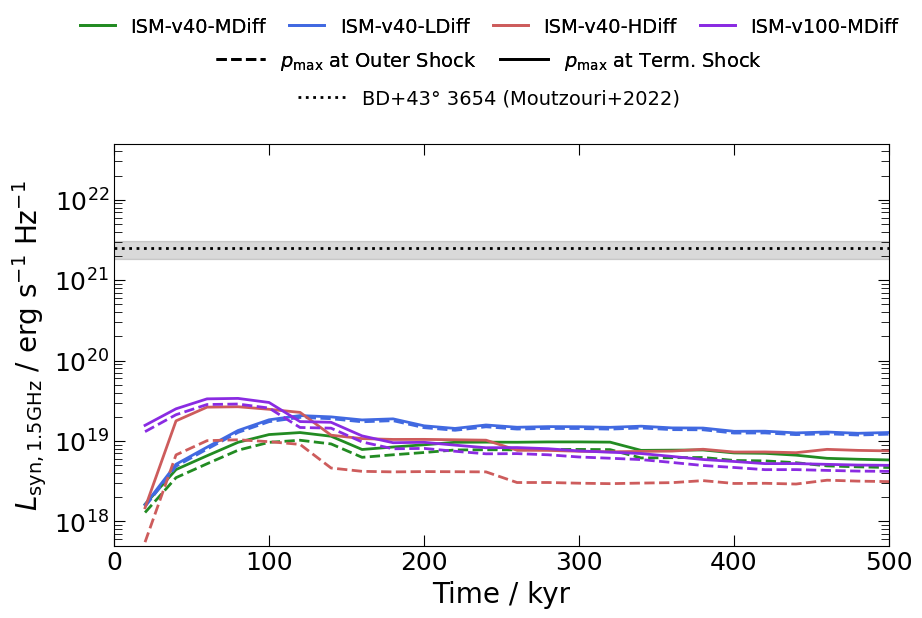

In [5]:
fig_tseries, ax_tseries = plt.subplots(figsize=(10, 6))

synch_freq = 1.5 * u.GHz  # choice of synchrotron frequency

sim_handles = []
for i, sim_name in enumerate(sim_names_compare):

    # --- outer shock pmax (dashed) ---
    with h5py.File(f"{data_dir}/emission_data_synch.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch.h5, skipping outer shock curve")
        else:
            times = pf[sim_name]["times"][()]
            synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz
            synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

            synch_freq_idx = np.digitize(synch_freq, synch_freq_grid, right=True)
            synch_lum = synch_lum[:, synch_freq_idx]

            times = times[np.argsort(times)]
            synch_lum = synch_lum[np.argsort(times)]

            times = times[synch_lum > 0]
            synch_lum = synch_lum[synch_lum > 0]

            ax_tseries.semilogy(
                times,
                synch_lum,
                color=bowshock_config[sim_name]["color"],
                label=bowshock_config[sim_name]["label"],
                ls="--",
                lw=2.0,
            )

    # --- termination shock pmax (solid) ---
    with h5py.File(f"{data_dir}/emission_data_synch_term.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch_term.h5, skipping termination shock curve")
        else:
            times = pf[sim_name]["times"][()]
            synch_freq_grid = pf[sim_name]["synch_freq"][()] * u.GHz
            synch_lum = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

            synch_freq_idx = np.digitize(synch_freq, synch_freq_grid, right=True)
            synch_lum = synch_lum[:, synch_freq_idx]

            times = times[np.argsort(times)]
            synch_lum = synch_lum[np.argsort(times)]

            times = times[synch_lum > 0]
            synch_lum = synch_lum[synch_lum > 0]

            ax_tseries.semilogy(
                times,
                synch_lum,
                color=bowshock_config[sim_name]["color"],
                label=bowshock_config[sim_name]["label"],
                ls="-",
                lw=2.0,
            )

    sim_handles.append(
        mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color=bowshock_config[sim_name]["color"],
            label=bowshock_config[sim_name]["label"],
        )
    )

# legend distinguishing outer shock vs termination shock pmax
pmax_handles = [
    mlines.Line2D([0], [0], lw=2.0, color="k", ls="--", label=r"$p_\mathrm{max}$ at Outer Shock"),
    mlines.Line2D([0], [0], lw=2.0, color="k", ls="-", label=r"$p_\mathrm{max}$ at Term. Shock"),
]

# plot BD+43 3654 data point (Moutzouri+2022) at the chosen frequency, as in plot_luminosities.ipynb
with h5py.File(f"{data_dir}/M22_data.h5", "r") as pf:
    vd = pf["BSBD43"]
    synch_freq_data = vd["freq"][()] * u.GHz
    freq_err = 0.5 * u.GHz  # width of each sub-band
    d, d_err = vd["D"][()] * u.kpc
    flux = vd["flux"][()] * 1e-12 * (u.erg * u.s**-1 * u.cm**-2)
    # pure flux is 5% calibration uncertainty, but data is nu * flux so we have to include
    # frequency error for flux error calculation
    flux_err = flux * np.sqrt(0.05**2 + (freq_err / synch_freq_data) ** 2)

    # calcualte luminosity
    synch_lum_data = (4 * np.pi * d**2 * flux).to(u.erg * u.s**-1)
    synch_lum_data_err = (
        4 * np.pi * np.sqrt((2 * d * flux * d_err) ** 2 + (d**2 * flux_err) ** 2)
    ).to(u.erg * u.s**-1)

    synch_lum_per_freq_data = (synch_lum_data / synch_freq_data).to(u.erg * u.s**-1 * u.Hz**-1)
    synch_lum_per_freq_data_err = (
        synch_lum_data_err / synch_freq_data
    ).to(u.erg * u.s**-1 * u.Hz**-1)

# find the data point closest to the chosen frequency
synch_lum_per_freq_data_freq = synch_lum_per_freq_data[
    np.digitize(synch_freq, synch_freq_data, right=True)
]
synch_lum_per_freq_data_freq_err = synch_lum_per_freq_data_err[
    np.digitize(synch_freq, synch_freq_data, right=True)
]

data_handle = ax_tseries.axhline(
    synch_lum_per_freq_data_freq.value,
    color="k",
    ls=":",
    alpha=1.0,
    label="BD+43° 3654 (Moutzouri+2022)",
    lw=2.0
)

ax_tseries.fill_between(
    np.linspace(-20, 600, 100),
    (synch_lum_per_freq_data_freq - synch_lum_per_freq_data_freq_err).value,
    (synch_lum_per_freq_data_freq + synch_lum_per_freq_data_freq_err).value,
    color="k",
    alpha=0.15,
    zorder=0
)

data_handles = [data_handle]

ax_tseries.set_xlabel("Time / kyr", fontsize=20)
ax_tseries.set_ylabel(
    rf"$L_\mathrm{{syn, {synch_freq:.1f}}}$ / erg s$^{{-1}}$ Hz$^{{-1}}$", fontsize=20
)

# ylimits
ax_tseries.set_xlim(xmin=0, xmax=500)
ax_tseries.set_ylim(ymin=5e17, ymax=5e22)

# ticks
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
    top=True,
)
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
    top=True,
)

# reserve headroom above the axes for the stacked legends
fig_tseries.subplots_adjust(top=0.78)

# three legend groups stacked in rows above the figure, each centered and
# sized to its own content (figure-fraction coords, so this is independent
# of the axes layout and needs no per-label hand-tuning)
leg1 = fig_tseries.legend(
    handles=sim_handles,
    prop={"size": 14},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.93],
    ncol=len(sim_handles),
    columnspacing=1.2,
    handlelength=1.8,
    frameon=False,
)
fig_tseries.add_artist(leg1)
leg2 = fig_tseries.legend(
    handles=pmax_handles,
    prop={"size": 14},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.87],
    ncol=len(pmax_handles),
    columnspacing=1.2,
    handlelength=2.5,
    frameon=False,
)
fig_tseries.add_artist(leg2)
fig_tseries.legend(
    handles=data_handles,
    prop={"size": 14},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.81],
    ncol=len(data_handles),
    columnspacing=1.2,
    handlelength=2.5,
    frameon=False,
)

fig_tseries.savefig(
    f"{fig_dir}/synch_lum_timeseries_outer_vs_term.pdf", bbox_inches="tight", dpi=300
)

### Ratio of termination shock to outer shock synchrotron luminosity: time-dependent

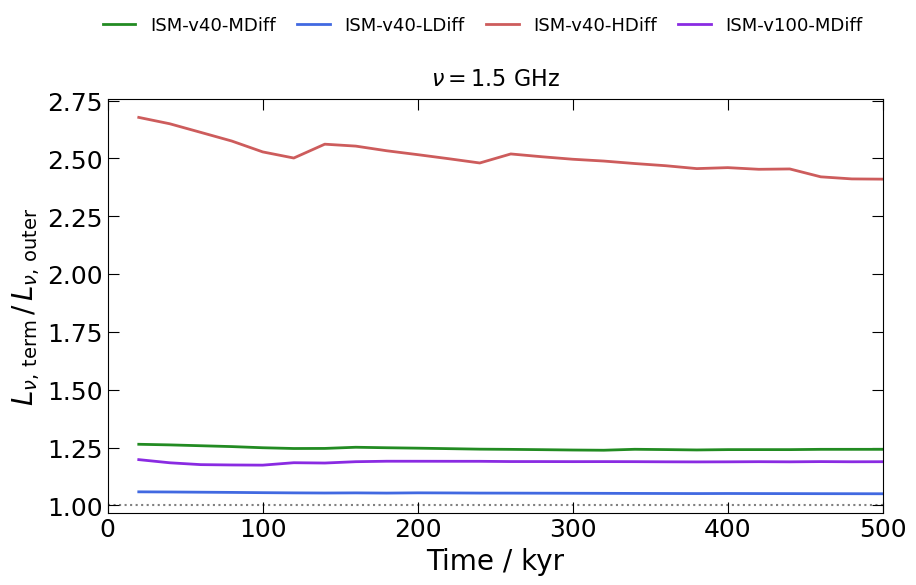

In [10]:

synch_freq_ratio = 1.5 * u.GHz  # choice of synchrotron frequency, matching the plot above

fig_ratio_t, ax_ratio_t = plt.subplots(figsize=(10, 6))

sim_handles = []
for i, sim_name in enumerate(sim_names_compare):

    with h5py.File(f"{data_dir}/emission_data_synch.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch.h5, skipping")
            continue
        times_outer = pf[sim_name]["times"][()]
        synch_freq_grid_outer = pf[sim_name]["synch_freq"][()] * u.GHz
        synch_lum_outer = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

        sort_idx = np.argsort(times_outer)
        times_outer = times_outer[sort_idx]
        freq_idx_outer = np.digitize(synch_freq_ratio, synch_freq_grid_outer, right=True)
        synch_lum_outer = synch_lum_outer[sort_idx, freq_idx_outer]

    with h5py.File(f"{data_dir}/emission_data_synch_term.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch_term.h5, skipping")
            continue
        times_term = pf[sim_name]["times"][()]
        synch_freq_grid_term = pf[sim_name]["synch_freq"][()] * u.GHz
        synch_lum_term = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

        sort_idx = np.argsort(times_term)
        times_term = times_term[sort_idx]
        freq_idx_term = np.digitize(synch_freq_ratio, synch_freq_grid_term, right=True)
        synch_lum_term = synch_lum_term[sort_idx, freq_idx_term]

    # common time grid: overlap of the two time ranges, sampled at the finer resolution
    t_min = max(times_outer.min(), times_term.min())
    t_max = min(times_outer.max(), times_term.max())
    n_t = max(len(times_outer), len(times_term))
    times_common = np.linspace(t_min, t_max, n_t)

    lum_outer_interp = np.interp(times_common, times_outer, synch_lum_outer.to_value(u.erg / u.s / u.Hz))
    lum_term_interp = np.interp(times_common, times_term, synch_lum_term.to_value(u.erg / u.s / u.Hz))

    valid = (lum_outer_interp > 0) & (lum_term_interp > 0)
    ratio_term_outer = lum_term_interp[valid] / lum_outer_interp[valid]

    ax_ratio_t.plot(
        times_common[valid],
        ratio_term_outer,
        color=bowshock_config[sim_name]["color"],
        label=bowshock_config[sim_name]["label"],
        lw=2.0,
    )

    sim_handles.append(
        mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color=bowshock_config[sim_name]["color"],
            label=bowshock_config[sim_name]["label"],
        )
    )

ax_ratio_t.axhline(1.0, color="grey", ls=":", lw=1.5, zorder=0)

ax_ratio_t.set_xlabel("Time / kyr", fontsize=20)
ax_ratio_t.set_ylabel(
    r"$L_{\nu,\,\mathrm{term}} \, / \, L_{\nu,\,\mathrm{outer}}$",
    fontsize=20,
)
ax_ratio_t.set_title(rf"$\nu = {synch_freq_ratio.value:g}$ GHz", fontsize=16, pad=10)

# xlimits, matching the luminosity vs time plot above
ax_ratio_t.set_xlim(xmin=0, xmax=500)

# ticks
ax_ratio_t.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
    top=True,
)
ax_ratio_t.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
    top=True,
)

fig_ratio_t.subplots_adjust(top=0.80)
fig_ratio_t.legend(
    handles=sim_handles,
    prop={"size": 13},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.88],
    ncol=len(sim_handles),
    columnspacing=1.2,
    handlelength=1.8,
    frameon=False,
)

fig_ratio_t.savefig(
    f"{fig_dir}/synch_lum_ratio_term_over_outer_timeseries.pdf", bbox_inches="tight", dpi=300
)


### Ratio of termination shock to outer shock synchrotron luminosity: time-averaged

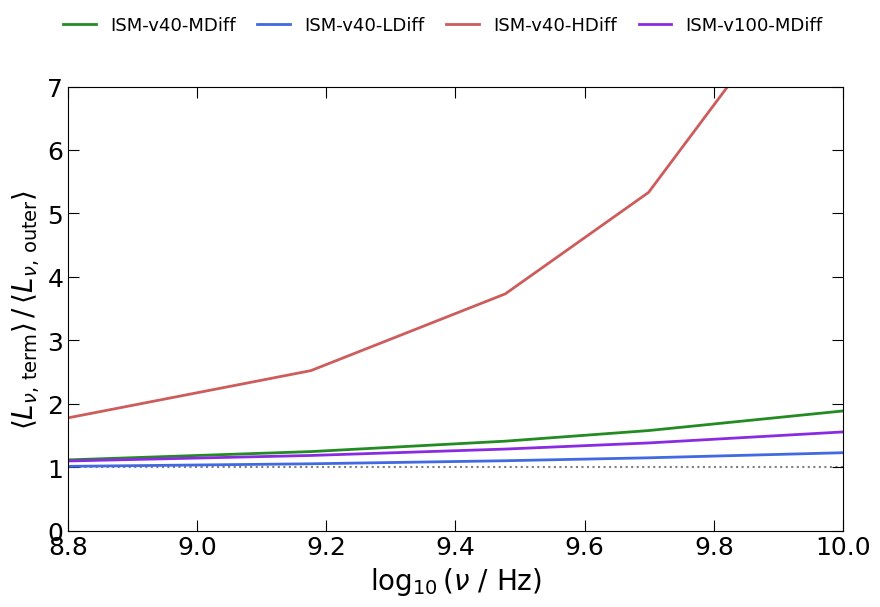

In [9]:

fig_ratio_f, ax_ratio_f = plt.subplots(figsize=(10, 6))

sim_handles = []
for i, sim_name in enumerate(sim_names_compare):

    with h5py.File(f"{data_dir}/emission_data_synch.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch.h5, skipping")
            continue
        times_outer = pf[sim_name]["times"][()] * u.kyr
        synch_freq_grid_outer = pf[sim_name]["synch_freq"][()] * u.GHz
        synch_lum_outer = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

        synch_lum_outer = synch_lum_outer[np.argsort(times_outer)]
        synch_lum_outer_tavg = np.mean(synch_lum_outer, axis=0)

    with h5py.File(f"{data_dir}/emission_data_synch_term.h5", "r") as pf:
        if sim_name not in pf.keys():
            print(f"{sim_name} not found in emission_data_synch_term.h5, skipping")
            continue
        times_term = pf[sim_name]["times"][()] * u.kyr
        synch_freq_grid_term = pf[sim_name]["synch_freq"][()] * u.GHz
        synch_lum_term = pf[sim_name]["synch_lum"][()] * (u.erg / u.s / u.Hz)

        synch_lum_term = synch_lum_term[np.argsort(times_term)]
        synch_lum_term_tavg = np.mean(synch_lum_term, axis=0)

    # both shocks share the same frequency grid, so a direct ratio is fine; if that ever
    # changes this should interpolate one onto the other's grid first
    assert synch_freq_grid_outer.shape == synch_freq_grid_term.shape
    ratio_term_outer_tavg = synch_lum_term_tavg / synch_lum_outer_tavg

    ax_ratio_f.plot(
        np.log10(synch_freq_grid_outer.to_value(u.Hz)),
        ratio_term_outer_tavg.to_value(u.dimensionless_unscaled),
        color=bowshock_config[sim_name]["color"],
        label=bowshock_config[sim_name]["label"],
        lw=2.0,
    )

    sim_handles.append(
        mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color=bowshock_config[sim_name]["color"],
            label=bowshock_config[sim_name]["label"],
        )
    )

ax_ratio_f.axhline(1.0, color="grey", ls=":", lw=1.5, zorder=0)

ax_ratio_f.set_xlabel(r"$\log_{10}(\nu$ / Hz)", fontsize=20)
ax_ratio_f.set_ylabel(
    r"$\langle L_{\nu,\, \mathrm{term}} \rangle \, / \, \langle L_{\nu,\, \mathrm{outer}} \rangle$",
    fontsize=20,
)
# ax_ratio_f.set_yscale("log")
ax_ratio_f.set_ylim(0, 7)
# xlimits, matching the time-averaged luminosity vs frequency plot above
ax_ratio_f.set_xlim(8.8, 10)

# ticks
ax_ratio_f.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
    top=True,
)
ax_ratio_f.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
    top=True,
)

fig_ratio_f.subplots_adjust(top=0.85)
fig_ratio_f.legend(
    handles=sim_handles,
    prop={"size": 13},
    loc="lower center",
    bbox_to_anchor=[0.5, 0.91],
    ncol=len(sim_handles),
    columnspacing=1.2,
    handlelength=1.8,
    frameon=False,
)

fig_ratio_f.savefig(
    f"{fig_dir}/synch_lum_ratio_term_over_outer_tavg_vs_freq.pdf", bbox_inches="tight", dpi=300
)
